# Dataset Pima Diabetes

Ce jeu de données est composé de 768 patientes appartenant à une population d'Amérindiens de l'Arizona, suivie depuis 1965 par le NIDDK (National Institute of Diabetes and Digestive and Kidney Diseases) pour son incidence élevée de diabète. Dans l'article original de Smith et al. ("Using the ADAP Learning Algorithm to Forecast the Onset of Diabetes Mellitus", 1988), les auteurs utilisent le réseau de neurones ADAP pour prédire la survenue d'un diabète entre 1 et 5 ans, représenté par la variable Outcome = 1. Le critère diagnostique est le test d'hyperglycémie provoquée par voie orale, effectué tous les 2 ans. Il est positif si, après ingestion de 75g de glucose, la glycémie est supérieure ou égale à 200 mg/dL (soit 2 g/L).

Nous allons analyser l'échantillon en question, puis déterminer les variables avec les corrélations les plus fortes, et finalement comparer les résultats de prédiction avec différents modèles.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#Mettre des noms sur les colonnes
colonnes = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
            "Insulin", "IMC", "DiabetesPedigreeFunction", "Age", "Outcome"]

df = pd.read_csv("pima-indians-diabetes.csv", names=colonnes)
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,IMC,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## Étape 1 : analyse de notre échantillon 
- 1° Y a-t-il des valeurs manquantes ?
- 2° Qui sont les patientes de ce dataset ?
- 3° Quelle est le pourcentage de diabétiques survenus dans les 5 ans ?
- 4° Y a-t-il des différences entre les groupes diabétiques et non-diabétiques ?

In [2]:
#Combien y a-t-il de valeurs manquantes (zéros) ?
#Prendre uniquement les colonnes avec des valeurs manquantes sauf Pregnancies et Outcome
colonnes_a_nettoyer = []
for i in df.drop(columns =["Pregnancies", "Outcome"]):
    if ((df[i] == 0).sum() != 0):
        colonnes_a_nettoyer.append(i)

#Remplacer ces valeurs par NaN
df[colonnes_a_nettoyer] = df[colonnes_a_nettoyer].replace(0, np.nan)
print(df.isnull().sum())


Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
IMC                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


On peut voir qu'il y a beaucoup de valeurs manquantes dans les colonnes insuline et épaisseur de la peau. On en a 374 sur 768 pour l'insuline (49%), 227 sur 768 pour l'épaisseur de peau (soit 30 %).

In [ ]:
#Quelle est le pourcentage de diabétiques survenus dans les 5 ans (268/768)
risque_5_ans = (df["Outcome"].sum()) / (df["Outcome"].count())
print(f"Le pourcentage de diabétiques survenus dans les 5 ans est de {risque_5_ans:.1%}")

Pourcentage de diabétiques survenus dans les 5 ans est de 34.9%


In [4]:
#Calculer le pourcentage de personnes dans chaque tranche de l'échelle d'IMC
bins = [0, 18.5, 25, 30, 35, 40, float("inf")]
labels = ["Maigreur", "Normal", "Surpoids", "Obésité I", "Obésité II", "Obésité III"]
classes = pd.cut(df["IMC"], bins=bins, labels=labels, right=False)
print(round((classes.value_counts(normalize=True).sort_index() * 100), 2))

#value_counts(normalize=True) -> compte les lignes par tranche et renvoie des proportions (entre 0 et 1) au lieu de nombres bruts.
#.sort_index() remet les tranches dans l'ordre naturel (sinon elles sont triées de la plus fréquente à la moins fréquente).

IMC
Maigreur        0.53
Normal         13.47
Surpoids       23.65
Obésité I      29.59
Obésité II     19.82
Obésité III    12.95
Name: proportion, dtype: float64


Pour avoir un élément de comparaison, voici les statistiques dans la population française d'après l'Enquête épidémiologique nationale (ObÉpi-Roche / OFEO) mise à jour par la Ligue contre l'obésité :
- 1- Insuffisance pondérale (Maigreur) | IMC inférieur à 18,5 | 4,5 %
- 2- Corpulence normale | IMC entre 18,5 et 24,9 | 48,2 %
- 3- Surpoids | IMC entre 25,0 et 29,9 | 30,3 %
- 4- Obésité modérée (Classe I) | IMC entre 30,0 et 34,9 | 11,9 %
- 5- Obésité sévère (Classe II) | IMC entre 35 et 39,9 | 3,1 %
- 6- Obésité morbide (Classe III) | IMC > 40 | 2 %

Nous avons environ 62,4 % des patientes en obésité (classe I, II et III), contre 17 % dans la population française.

Attention, l'enquête ObEpi est auto-déclarée, les IMC sont sûrement sous-estimés.

In [5]:
#Quel est l'âge moyen et médian ; on regarde la distribution de la colonne Age 
print("Voici la distribution complète","\n",df["Age"].describe())

#Répartition par tranche d'âge
bins = [20, 30, 40, 50, float("inf")]
labels = ["Entre 20 et 29", "Entre 30 et 39", "Entre 40 et 49", "50 et au-dessus"]
repartition_age = pd.cut(df.Age, bins=bins, labels=labels, right=False)
print("Répartition par tranche d'âge en % :", repartition_age.value_counts(normalize=True).sort_index()*100)

#Le taux de diabète survenu dans les 5 ans change-t-il d'une tranche à l'autre
taux_diabetes_par_tranche = (df.groupby(repartition_age, observed=False)["Outcome"].mean()*100)
print("Taux de diabète survenu dans les 5 ans, par tranche d'âge en % :", taux_diabetes_par_tranche)

Voici la distribution complète 
 count    768.000000
mean      33.240885
std       11.760232
min       21.000000
25%       24.000000
50%       29.000000
75%       41.000000
max       81.000000
Name: Age, dtype: float64
Répartition par tranche d'âge en % : Age
Entre 20 et 29     51.562500
Entre 30 et 39     21.484375
Entre 40 et 49     15.364583
50 et au-dessus    11.588542
Name: proportion, dtype: float64
Taux de diabète survenu dans les 5 ans, par tranche d'âge en % : Age
Entre 20 et 29     21.212121
Entre 30 et 39     46.060606
Entre 40 et 49     55.084746
50 et au-dessus    48.314607
Name: Outcome, dtype: float64


D'après l'article les patientes sélectionnées avaient au moins 21 ans, ce qui est confirmé par un âge minimum de 21. De plus la distribution est très asymétrique, avec une majorité de jeunes patientes et une minorité plus âgée qui tire la moyenne vers le haut. En effet, la médiane (29 ans) est inférieure à la moyenne (33 ans). La médiane décrit donc mieux la patiente typique de cet échantillon. Ces données ne peuvent donc pas être généralisées à une population plus âgée. De plus, on peut voir que le taux de diabète survenu dans les 5 ans dans la tranche de 20 à 29 ans, là où nous avons 51,6 % des femmes de l'échantillon, n'est que de 21,2 %, c'est-à-dire le plus faible des 4 tranches.

In [6]:
#Déterminer le pourcentage de personnes avec une PAD >= 90 (catégorie BloodPressure)
groupe_forte_pad = df["BloodPressure"].map(lambda p : p >= 90).sum()
pourcentage_groupe_pad = groupe_forte_pad / df["BloodPressure"].count()
print(f"Pourcentage de personnes avec une PAD supérieure ou égale à 90 mmHg = {pourcentage_groupe_pad:.1%}")

Pourcentage de personnes avec une PAD supérieure ou égale à 90 mmHg = 8.2%


Santé Publique France définit l'hypertension artérielle (HTA) par une PAS ≥ 140 et/ou une PAD ≥ 90 (ou par un traitement antihypertenseur). Elle détermine dans la population adulte française, une prévalence globale de l'HTA de 30,6%. En regardant selon l'âge, elle est de 6,3 % pour les 18-34 ans et de 67,8 % pour les 65-74 ans. On pourrait dire que notre taux de 8,2 %, qui peut s'apparenter à de l'HTA, est supérieur à celui de la population des 18-34 ans, puisque 75 % de l'échantillon ont 41 ans ou moins. Cette comparaison reste approximative, car les deux populations sont très différentes et nous avons uniquement la valeur de PAD dans notre échantillon, on sous-estime probablement la présence d'hypertension.

In [7]:
#Comparer les moyennes et les médianes entre les deux groupes (version en une seule ligne)
comparaison_moy_2_grp = df.groupby("Outcome")[["Glucose", 'BloodPressure', "SkinThickness", "Insulin", "IMC", "DiabetesPedigreeFunction", "Age"]].agg(["mean", "median"])
print(comparaison_moy_2_grp)

            Glucose        BloodPressure        SkinThickness         \
               mean median          mean median          mean median   
Outcome                                                                
0        110.643863  107.0     70.877339   70.0     27.235457   27.0   
1        142.319549  140.0     75.321429   74.5     33.000000   32.0   

            Insulin               IMC        DiabetesPedigreeFunction         \
               mean median       mean median                     mean median   
Outcome                                                                        
0        130.287879  102.5  30.859674   30.1                 0.429734  0.336   
1        206.846154  169.5  35.406767   34.3                 0.550500  0.449   

               Age         
              mean median  
Outcome                    
0        31.190000   27.0  
1        37.067164   36.0  


Le groupe diabétique a des moyennes et des médianes systématiquement supérieures.

## Étape 2 : visualisation et corrélations
- Quelles sont les variables qui semblent le plus associées au diabète ?

Voici la corrélation entre Glucose et IMC : 0.23277051103551305


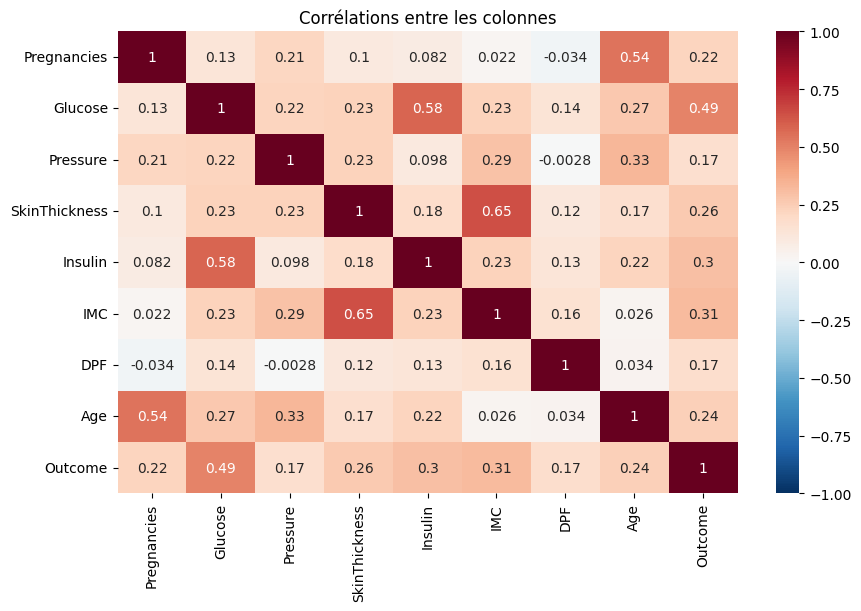

In [8]:
#Trouver une corrélation
test_de_correlation = df["Glucose"].corr(df.IMC)
print("Voici la corrélation entre Glucose et IMC :", test_de_correlation)

#Visualisation des corrélations entre colonnes
correlation = df.corr()
plt.figure(figsize=(10,6))
tick_labels = ("Pregnancies", "Glucose", "Pressure", "SkinThickness", "Insulin", "IMC", "DPF", "Age", "Outcome")
sns.heatmap(correlation, annot=True, vmax=1, vmin=-1, center=0, cmap="RdBu_r", yticklabels=tick_labels, xticklabels=tick_labels)
plt.title("Corrélations entre les colonnes")
plt.show()

In [9]:
#Établir les corrélations entre Outcome et toutes les colonnes (sans prendre en compte Outcome)
tableau_correlation = df.corr(numeric_only=True)["Outcome"].sort_values(ascending=False).drop("Outcome")
print(tableau_correlation)

#Vérifier le nombre de patientes utilisées pour les 3 corrélations les plus fortes
nbr_patientes = {}
for i in tableau_correlation.nlargest(3).index :
    nbr_patientes[i] = len(df[i]) - df[i].isna().sum()
    print(f"{i} calculé sur {nbr_patientes[i]} patientes")

Glucose                     0.494650
IMC                         0.313680
Insulin                     0.303454
SkinThickness               0.259491
Age                         0.238356
Pregnancies                 0.221898
DiabetesPedigreeFunction    0.173844
BloodPressure               0.170589
Name: Outcome, dtype: float64
Glucose calculé sur 763 patientes
IMC calculé sur 757 patientes
Insulin calculé sur 394 patientes


Dans cet échantillon, la variable la plus associée au diabète est le glucose (r = 0,49), nettement devant l'IMC (0,31) et l'insuline (0,30). Viennent ensuite l'épaisseur de peau, l'âge et le nombre de grossesses (0,22 à 0,26), puis la DPF et la pression artérielle (0,17). La corrélation de l'insuline repose sur environ la moitié des patientes seulement (394 patientes). 
Une corrélation mesure une association, pas une causalité.

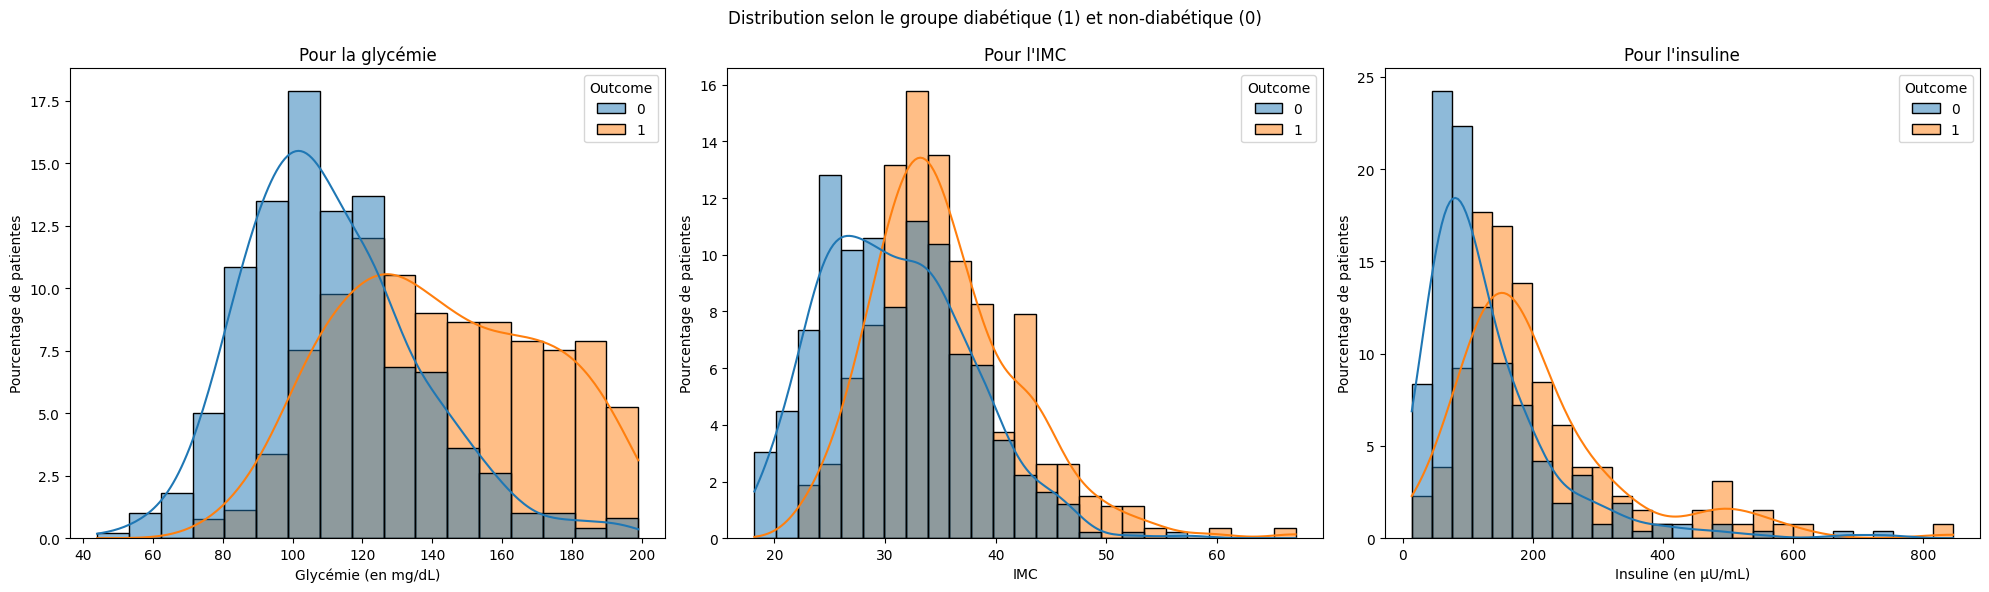

In [10]:
#Visualisation des 3 variables les plus corrélées sur une seule feuille
graphique_correlation, (page1, page2, page3) = plt.subplots(1, 3, figsize=(20,6))
graphique_correlation.suptitle("Distribution selon le groupe diabétique (1) et non-diabétique (0)")
sns.histplot(data = df, x='Glucose', kde = True, stat='percent', hue='Outcome', common_norm=False, ax=page1)
page1.set_title("Pour la glycémie")
page1.set_xlabel("Glycémie (en mg/dL)")
page1.set_ylabel("Pourcentage de patientes")
sns.histplot(data=df, x='IMC', kde=True, stat='percent', hue='Outcome', common_norm=False, ax=page2)
page2.set_title("Pour l'IMC")
page2.set_xlabel("IMC")
page2.set_ylabel("Pourcentage de patientes")
sns.histplot(data=df, x='Insulin', kde=True, stat='percent', hue='Outcome', common_norm=False, ax=page3)
page3.set_title("Pour l'insuline")
page3.set_xlabel("Insuline (en µU/mL)")
page3.set_ylabel("Pourcentage de patientes")
plt.tight_layout()
plt.show()

In [11]:
#Boucle de calcul de l'intervalle de confiance pour les 3 corrélations les plus fortes
from scipy.stats import pearsonr
valeur_top_3 = tableau_correlation.nlargest(3).index
for i in valeur_top_3:
    calcul = df[[i, "Outcome"]].dropna()
    ma_valeur = pearsonr(x = calcul[i], y = calcul["Outcome"])
    print(f"{i} : r = {ma_valeur.statistic:.2f}, n = {len(calcul)} patientes ; IC 95% [{ma_valeur.confidence_interval(0.95).low:.2} ; {ma_valeur.confidence_interval(0.95).high:.2}] ; p = {ma_valeur.pvalue:.1e}")

Glucose : r = 0.49, n = 763 patientes ; IC 95% [0.44 ; 0.55] ; p = 2.5e-48
IMC : r = 0.31, n = 757 patientes ; IC 95% [0.25 ; 0.38] ; p = 9.5e-19
Insulin : r = 0.30, n = 394 patientes ; IC 95% [0.21 ; 0.39] ; p = 7.8e-10


Sur les 768 patientes du DataFrame, nous pouvons voir que les trois variables les plus corrélées à Outcome sont le Glucose (r = 0,49 ; IC95 [0,44 ; 0,55]), l'IMC (r = 0,31 ; IC95 [0,25 ; 0,38]) et l'Insuline (r = 0,30 ; IC95 [0,21 ; 0,39]). Ces trois corrélations sont statistiquement significatives (p < 0,05). 

Sachant que l'insuline n'est mesurée que pour 394 patientes sur 768 (51%), et que certaines valeurs d'insuline sont extrêmement élevées, elles pourraient influencer la corrélation, nous allons donc la recalculer avec la méthode IQR.

Nombre de patientes au total = 744 ; Nombre de patientes NaN = 374
24 patientes ont été retirées


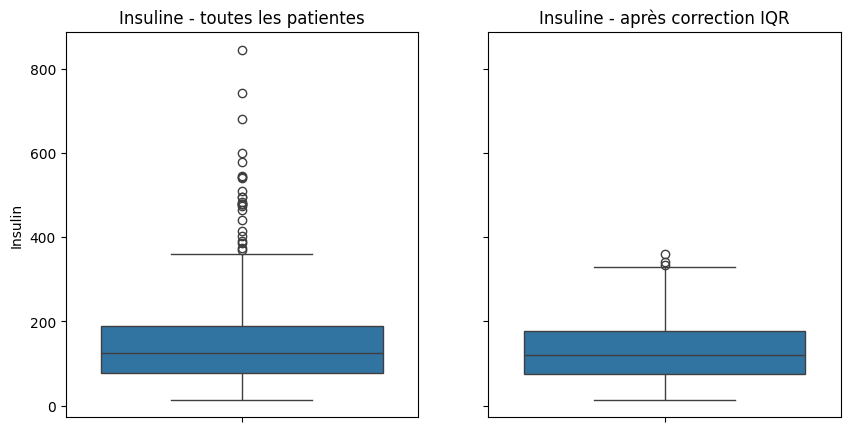

r = 0.33 ; n = 370 patientes ; IC 95% [0.24 ; 0.42]


In [12]:
#Méthode IQR
Q1_insulin = df["Insulin"].quantile(0.25)
Q3_insulin = df["Insulin"].quantile(0.75)
IQR_insulin = Q3_insulin - Q1_insulin
born_inf_insulin = Q1_insulin - 1.5 * IQR_insulin
born_sup_insulin = Q3_insulin + 1.5 * IQR_insulin

#Retirer ces valeurs dans la colonne Insuline tout en gardant les patientes avec NaN
df_clean = df.loc[((df["Insulin"] >= born_inf_insulin) & (df["Insulin"] <= born_sup_insulin))|(df["Insulin"].isnull())]
print(f"Nombre de patientes au total = {len(df_clean)} ; Nombre de patientes NaN = {df_clean['Insulin'].isna().sum()}")
print(f"{len(df['Insulin']) - len(df_clean)} patientes ont été retirées")

#Faire une feuille avec les deux distributions avant/après le nettoyage (même échelle)
fig_clean, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
sns.boxplot(y=df["Insulin"], ax=ax1)
ax1.set_title("Insuline - toutes les patientes")
sns.boxplot(y=df_clean["Insulin"], ax=ax2)
ax2.set_title("Insuline - après correction IQR")
plt.show(fig_clean)

#Recalculer la corrélation 
new_colonnes = df_clean[["Insulin", "Outcome"]].dropna()
new_corr_insulin = pearsonr(x = new_colonnes["Insulin"], y = new_colonnes["Outcome"])
print(f"r = {new_corr_insulin.statistic:.2f} ; n = {len(new_colonnes)} patientes ; IC 95% [{new_corr_insulin.confidence_interval(0.95).low:.2} ; {new_corr_insulin.confidence_interval(0.95).high:.2}]")

La méthode IQR identifie 24 valeurs d'insuline extrêmes. Au final, leur suppression ne modifie pas la conclusion : r = 0,33 contre 0,30 auparavant. Ces valeurs élevées sont physiologiquement plausibles, sachant la forte insulino-résistance des patientes de cette population. Elles ont donc été conservées dans l'analyse principale.

La corrélation mesure un lien entre deux variables et ne permet pas de conclure à une causalité.

## Étape 3 : modèles de prédiction
- Comparer les résultats de l'étude avec un modèle Forêt Aléatoire
- Comparer les résultats de l'étude avec un modèle de Régression Logistique

In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import cross_val_predict
from sklearn.model_selection import cross_validate

#Définir les features et la cible
y = df.Outcome
X = df.drop("Outcome", axis=1)

#Le premier modèle est un Random Forest
first_model = RandomForestClassifier(random_state=1)
first_prediction = cross_val_score(first_model, X, y, cv=5, scoring="accuracy")
first_auc = cross_val_score(first_model, X, y, cv=5, scoring="roc_auc")
print(f"La proportion de prédictions correctes est de {first_prediction.mean():.1%}, avec une AUC de {first_auc.mean():.3f}")

#Le deuxième modèle sera une régression logistique (à l'intérieur d'une pipeline)
second_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
    ("second_model", LogisticRegression(random_state=1))
    ])
second_prediction = cross_validate(second_pipeline, X, y, cv=5, scoring=["accuracy", "roc_auc"])
print(f"La proportion de prédictions correctes est de {second_prediction['test_accuracy'].mean():.1%}, avec une AUC de {second_prediction['test_roc_auc'].mean():.3f}")

#Comparaison avec un modèle qui ne ferait rien, qui prédirait toujours outcome = 0 
comparaison_tjrs_diabete = 1 - (df["Outcome"].sum()) / (df["Outcome"].count())
print(f"Un modèle qui ne prédit aucun risque de diabète a une accuracy de {comparaison_tjrs_diabete:.1%}")

La proportion de prédictions correctes est de 77.2%, avec une AUC de 0.836
La proportion de prédictions correctes est de 76.8%, avec une AUC de 0.842
Un modèle qui ne prédit aucun risque de diabète a une accuracy de 65.1%


Le modèle ADAP est évalué au point de croisement où la sensibilité est à peu près égale à la spécificité. Dans l'article il est de 76 %. Nous devons donc déterminer ce même point pour nos deux modèles et comparer les résultats.

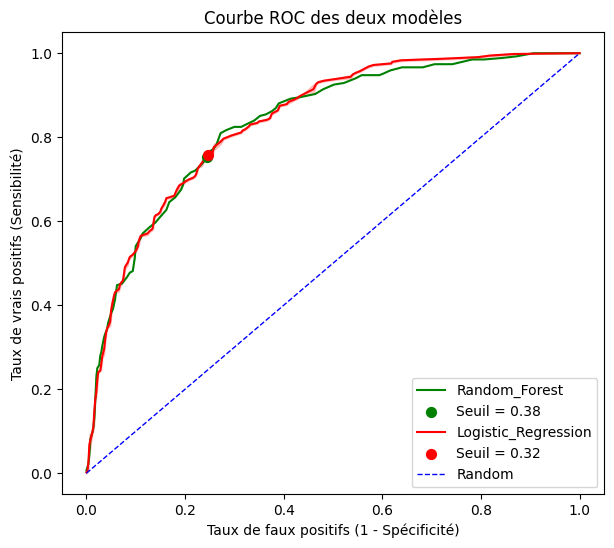

Nous avons pour le modèle Random Forest une spécificité de 0.756 comprise entre [0.718 ; 0.794] et une sensibilité de 0.754 comprise entre [0.702 ; 0.805] au seuil de 0.38
Nous avons pour le modèle de Régression logistique une spécificité de 0.754 comprise entre [0.716 ; 0.792] et une sensibilité de 0.757 comprise entre [0.706 ; 0.809] au seuil de 0.32
Au point de croisement la sensibilité et la spécificité du modèle ADAP valent 76 %, comprise entre [0.685 ; 0.835] pour la spécificité et entre [0.658 ; 0.862] pour la sensibilité


In [ ]:
#Calculer directement les courbes ROC pour les deux modèles précédents
from sklearn.metrics import roc_curve
def courbe_roc_model(model):
    model_proba = cross_val_predict(model, X, y, cv=5, method='predict_proba')
    model_roc_curve = roc_curve(y_true=y, y_score=model_proba[:, 1])
    return model_roc_curve

first_roc = courbe_roc_model(first_model)
second_roc = courbe_roc_model(second_pipeline)

#Trouver les points de croisement où sensibilité = spécificité 
#La fonction roc_curve donne 3 tableaux dans l'ordre : fpr (0), tpr (1) et les seuils (2)
def trouver_le_point_de_croisement(roc_curve_model):
    x = abs(roc_curve_model[1]-(1-roc_curve_model[0])).argmin()
    return(1-roc_curve_model[0][x], roc_curve_model[1][x], roc_curve_model[2][x])

sp_forest, se_forest, seuil_croisement_forest = trouver_le_point_de_croisement(first_roc)
sp_logreg, se_logreg, seuil_croisement_logreg = trouver_le_point_de_croisement(second_roc)

#Tracer les courbes ROC et le point de croisement
plt.figure(figsize=(7,6))
plt.title("Courbe ROC des deux modèles")
plt.ylabel("Taux de vrais positifs (Sensibilité)")
plt.xlabel("Taux de faux positifs (1 - Spécificité)")
sns.lineplot(x=first_roc[0], y=first_roc[1], color="green", label='Random_Forest').scatter(x=(1-sp_forest), y=se_forest , color="green", s=50, zorder=5, label=f"Seuil = {seuil_croisement_forest:.2f}")
sns.lineplot(x=second_roc[0], y=second_roc[1], color="red", label='Logistic_Regression').scatter(x=(1-sp_logreg), y=se_logreg , color="red", s=50, zorder=5, label=f"Seuil = {seuil_croisement_logreg:.2f}")
plt.plot([0, 1], [0, 1], 'b--', linewidth=1, label='Random')
plt.legend()
plt.show()

#Calculer la marge d'erreur de nos modèles au niveau de confiance 95%
def marge_erreur(p, n):
    erreur = 1.96*(p*(1-p)/n)**(1/2)
    return erreur

#Le modèle ADAP a été testé sur 192 patientes, on suppose que le pourcentage de cas positifs est le même que pour les 768 patientes (environ 35 %)
erreur_se_ADAP, erreur_sp_ADAP = marge_erreur(0.76, risque_5_ans*192), marge_erreur(0.76, (1-risque_5_ans)*192)
erreur_se_RandomForest, erreur_sp_RandomForest = marge_erreur(se_forest, y.value_counts().loc[1]), marge_erreur(sp_forest, y.value_counts().loc[0])
erreur_se_LogReg, erreur_sp_LogReg = marge_erreur(se_logreg, y.value_counts().loc[1]), marge_erreur(sp_logreg, y.value_counts().loc[0])

print(f"Nous avons pour le modèle Random Forest une spécificité de {sp_forest:.3f} comprise entre [{sp_forest - erreur_sp_RandomForest:.3f} ; {sp_forest + erreur_sp_RandomForest:.3f}] et une sensibilité de {se_forest:.3f} comprise entre [{se_forest - erreur_se_RandomForest:.3f} ; {se_forest + erreur_se_RandomForest:.3f}] au seuil de {seuil_croisement_forest:.2f}")
print(f"Nous avons pour le modèle de Régression logistique une spécificité de {sp_logreg:.3f} comprise entre [{sp_logreg - erreur_sp_LogReg:.3f} ; {sp_logreg + erreur_sp_LogReg:.3f}] et une sensibilité de {se_logreg:.3f} comprise entre [{se_logreg - erreur_se_LogReg:.3f} ; {se_logreg + erreur_se_LogReg:.3f}] au seuil de {seuil_croisement_logreg:.2f}")
print(f"Au point de croisement la sensibilité et la spécificité du modèle ADAP valent 76 %, comprises entre [{0.76-erreur_sp_ADAP:.3f} ; {0.76+erreur_sp_ADAP:.3f}] pour la spécificité et entre [{0.76-erreur_se_ADAP:.3f} ; {0.76+erreur_se_ADAP:.3f}] pour la sensibilité")

Nous avons maintenant la possibilité de comparer le modèle ADAP de l'étude avec nos deux modèles. Le Random Forest et la régression logistique sont très similaires en termes de performance : que ce soit en accuracy, AUC, spécificité ou sensibilité. Cette similitude est particulièrement visible sur le graphique des deux courbes ROC. Nos modèles sont pratiquement équivalents à celui de l'étude au point de croisement où sensibilité = spécificité avec environ 75 % contre 76 %. Une chose à garder en tête est que le modèle ADAP a été entrainé sur 576 patientes puis testé sur 192 patientes une seule fois. De l'autre côté, avec la cross validation, nos modèles ont été entrainés puis testés sur respectivement 614 et 154 patientes à chacun des 5 tours. Les pourcentages obtenus par nos modèles semblent donc plus précis et plus fiables puisqu'ils sont calculés sur bien plus de patientes. On peut le constater par des marges d'erreur réduites par rapport au modèle ADAP. À noter que les 3 modèles gèrent les valeurs manquantes différemment, ce qui limite la comparaison.
Finalement, cela suggère qu'un modèle aussi simple qu'une régression logistique peut être aussi performant qu'un réseau de neurones complexe dans notre cas précis.